In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv(r"C:\Users\user\Downloads\archive (4)\StudentsPerformance.csv")

In [35]:
print("Original Dataset: ")
print(df)

Original Dataset: 
     gender race/ethnicity parental level of education         lunch  \
0    female        group B           bachelor's degree      standard   
1    female        group C                some college      standard   
2    female        group B             master's degree      standard   
3      male        group A          associate's degree  free/reduced   
4      male        group C                some college      standard   
..      ...            ...                         ...           ...   
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
0                      none          72     

In [36]:
print("First 5 rows of the dataset:")
print (df. head())
print ("\nDataset shape:")
print (df. shape)

First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  

Dataset shape:
(1000, 8)


In [37]:
data=df["math score"].dropna()
len(data)

1000

In [38]:
Q1 = data.quantile(0.25)

In [39]:
Q1


57.0

In [40]:
Q3 = data.quantile(0.75)

In [41]:
Q3

77.0

In [42]:
IQR = Q3 - Q1

In [43]:
IQR

20.0

In [44]:
lower_limit = Q1 - 1.5*IQR
upper_limit = Q3 + 1.5*IQR

In [45]:
lower_limit

27.0

In [46]:
upper_limit

107.0

In [47]:
outliers = df[
(data<lower_limit)|(data>upper_limit)
    ]

In [48]:
print(outliers)
print("\nLength of outliers")
print(len(outliers))


     gender race/ethnicity parental level of education         lunch  \
17   female        group B            some high school  free/reduced   
59   female        group C            some high school  free/reduced   
145  female        group C                some college  free/reduced   
338  female        group B            some high school  free/reduced   
466  female        group D          associate's degree  free/reduced   
787  female        group B                some college      standard   
842  female        group B                 high school  free/reduced   
980  female        group B                 high school  free/reduced   

    test preparation course  math score  reading score  writing score  
17                     none          18             32             28  
59                     none           0             17             10  
145                    none          22             39             33  
338                    none          24             38         

In [49]:
mean=data.mean()
std=data.std()

In [50]:
df["Z_score"]=(df["math score"]-mean)/std

z_outliers = df[abs(df["Z_score"])>3]

In [51]:
std

15.163080096009468

In [52]:
len(z_outliers)

4

In [53]:
z_outliers

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Z_score
17,female,group B,some high school,free/reduced,none,18,32,28,-3.171453
59,female,group C,some high school,free/reduced,none,0,17,10,-4.358547
787,female,group B,some college,standard,none,19,38,32,-3.105504
980,female,group B,high school,free/reduced,none,8,24,23,-3.830950


In [54]:
mean


66.089

In [55]:
print("\nIQR OUTLIERS")
if len(outliers) > 0:
  print(outliers[["math score"]])
else:
  print("No IQR outliers found.")
print("\n Z-SCORE OUTLIERS")
if len(z_outliers) > 0:
  print(z_outliers[["math score", "Z_score"]])
else:
  print("No Z-score outliers found")


IQR OUTLIERS
     math score
17           18
59            0
145          22
338          24
466          26
787          19
842          23
980           8

 Z-SCORE OUTLIERS
     math score   Z_score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [57]:
df["math score_treated"] = df["math score"].clip(lower=lower_limit, upper=upper_limit)
print("Treatment method: Capping using IQR limits")

Treatment method: Capping using IQR limits


In [58]:
print("\n BEFORE TREATMENT")
data.describe()


 BEFORE TREATMENT


count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

In [59]:
print("\n AFTER TREATMENT")
df["math score_treated"].describe()


 AFTER TREATMENT


count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math score_treated, dtype: float64

In [62]:
comparison=df[["math score","math_score_treated"]]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


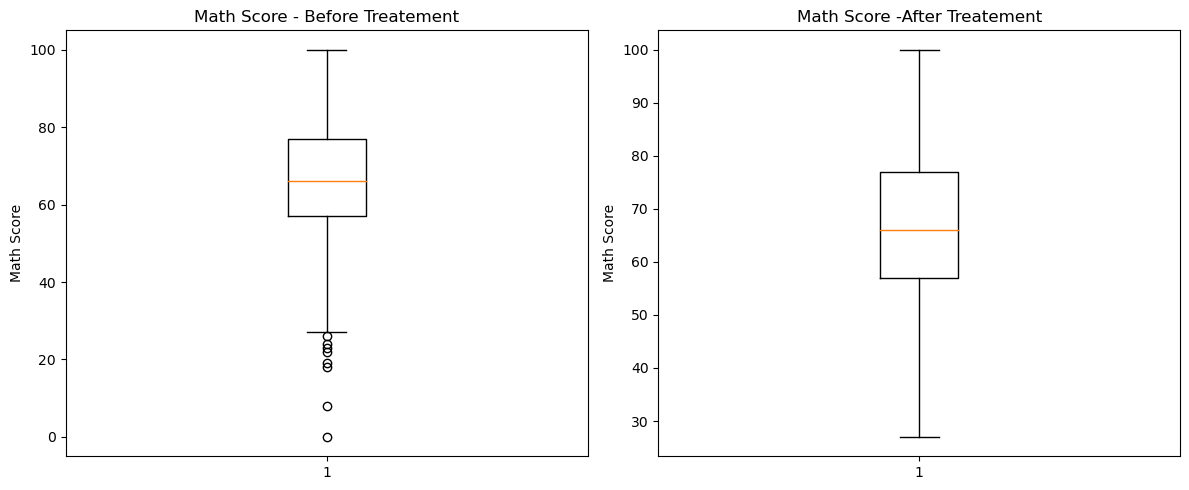

In [67]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - Before Treatement")
plt.ylabel("Math Score")

plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score -After Treatement")
plt.ylabel("Math Score")

plt.tight_layout()
plt.show()